# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'ym31'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

WLS: k = 0.2432 +/- 0.0097 mag/airmass, m0 = 25.0662 +/- 0.0162 mag
polyfit: k = 0.2432 +/- 0.0221
chi2 = 67.2, dof = 13, chi2/dof = 5.17
ratio of polyfit error to WLS error: 2.2733036265077584  sqrt(chi2/dof): 2.2733036265076607
P(chi2 >= 67.2) = 2.6e-09
P(chi2 <= 67.2) = 0.9999999974
without the worst point (-5.2 sigma): chi2/dof = 3.10
quadratic instead of a line: chi2 = 66.9


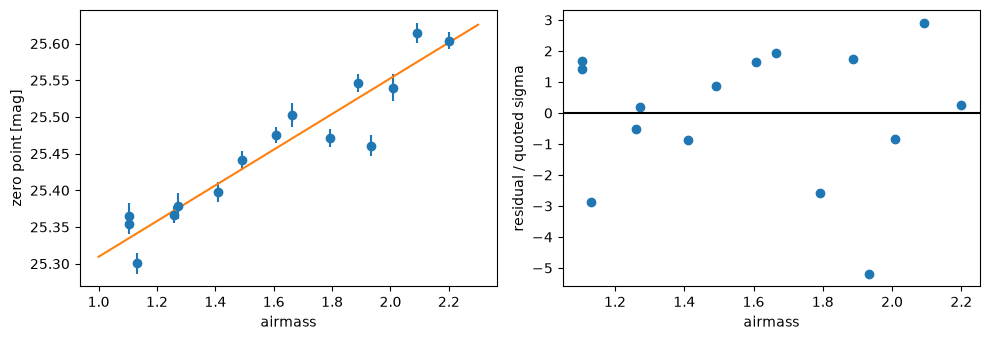

In [2]:
d = load('p1a_extinction')
X = d['airmass'].to_numpy()
zp = d['zeropoint_mag'].to_numpy()
sig = d['sigma_quoted_mag'].to_numpy()

# weighted least squares by the normal equations, errors from the quoted sigmas only
A = np.vstack([X, np.ones_like(X)]).T
Cinv = np.diag(1/sig**2)
Cw = np.linalg.inv(A.T @ Cinv @ A)
k, m0 = Cw @ A.T @ Cinv @ zp
print(f"WLS: k = {k:.4f} +/- {np.sqrt(Cw[0,0]):.4f} mag/airmass, m0 = {m0:.4f} +/- {np.sqrt(Cw[1,1]):.4f} mag")

p, Cpf = np.polyfit(X, zp, 1, w=1/sig, cov=True)
print(f"polyfit: k = {p[0]:.4f} +/- {np.sqrt(Cpf[0,0]):.4f}")

resid = (zp - A @ np.array([k, m0]))/sig
chi2 = np.sum(resid**2)
dof = len(X) - 2
print(f"chi2 = {chi2:.1f}, dof = {dof}, chi2/dof = {chi2/dof:.2f}")
print("ratio of polyfit error to WLS error:", np.sqrt(Cpf[0,0]/Cw[0,0]), " sqrt(chi2/dof):", np.sqrt(chi2/dof))
print(f"P(chi2 >= {chi2:.1f}) = {stats.chi2.sf(chi2, dof):.1e}")
print(f"P(chi2 <= {chi2:.1f}) = {stats.chi2.cdf(chi2, dof):.10f}")

# is it one bad point, or a wrong model?
worst = np.argmax(np.abs(resid))
ok = np.arange(len(X)) != worst
p_ok = np.polyfit(X[ok], zp[ok], 1, w=1/sig[ok])
chi2_ok = np.sum(((zp[ok] - np.polyval(p_ok, X[ok]))/sig[ok])**2)
print(f"without the worst point ({resid[worst]:.1f} sigma): chi2/dof = {chi2_ok/(ok.sum()-2):.2f}")
p2 = np.polyfit(X, zp, 2, w=1/sig)
print(f"quadratic instead of a line: chi2 = {np.sum(((zp - np.polyval(p2, X))/sig)**2):.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].errorbar(X, zp, sig, fmt='o')
xx = np.linspace(1, 2.3, 10)
ax[0].plot(xx, k*xx + m0)
ax[0].set_xlabel('airmass')
ax[0].set_ylabel('zero point [mag]')
ax[1].plot(X, resid, 'o')
ax[1].axhline(0, color='k')
ax[1].set_xlabel('airmass')
ax[1].set_ylabel('residual / quoted sigma')
plt.tight_layout()
plt.show()

**ANSWER:**

1. WLS with the quoted errors: $k = 0.2432 \pm 0.0097$ mag/airmass.

2. `polyfit` gives $k = 0.2432 \pm 0.022$ mag/airmass, so same slope but a 2.27x bigger error. With `cov=True` numpy scales the covariance by $\chi^2/\nu$ (it treats the weights as relative and gets the overall noise level from the residuals, you need `cov='unscaled'` to turn that off). $\sqrt{\chi^2/\nu} = \sqrt{5.17} = 2.27$, exactly the ratio.

3. $\chi^2 = 67.2$ with $\nu = 13$. If the quoted errors were right, $P(\chi^2 \ge 67.2) = 2.6\times10^{-9}$, so basically never, and $P(\chi^2 \le 67.2) \approx 1$, so it's way too large, not too small.

4. I'd quote $k = 0.243 \pm 0.022$ mag/airmass (the rescaled one). The residuals don't show a trend with airmass and a quadratic only lowers $\chi^2$ from 67.2 to 66.9, so the line is fine, and it's not one bad point either (dropping the worst one still gives $\chi^2/\nu = 3.1$). So the pipeline errors look too small by ~2.3 on every point, probably a missing noise term. Rescaling is only ok here because the model itself looks right.

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [3]:
b = load('p1b_centroid')
psf = b['psf_sigma_arcsec'][0]
N = b['n_photons'][0]
quoted = b['quoted_sigma_x0_arcsec'][0]
crb = psf/np.sqrt(N)
print(f"PSF sigma = {psf:.3f} arcsec, N = {N} photons")
print(f"Cramer-Rao bound: {crb:.4f} arcsec, quoted: {quoted:.4f} arcsec, bound/quoted = {crb/quoted:.2f}")
print(f"(bound/quoted)^2 = {(crb/quoted)**2:.2f}")

PSF sigma = 1.316 arcsec, N = 396 photons
Cramer-Rao bound: 0.0661 arcsec, quoted: 0.0450 arcsec, bound/quoted = 1.47
(bound/quoted)^2 = 2.16


**ANSWER:**

1. $\sigma_{x_0} \ge \sigma_{\rm PSF}/\sqrt{N} = 1.316/\sqrt{396} = 0.066$ arcsec.

2. Not possible, 0.045 arcsec is 1.47x below the bound and no unbiased estimator can beat it no matter how you weight. So it's either the error of a biased estimator or just wrong. $(0.066/0.045)^2 = 2.2$, so it's what you'd get with ~2.2x more photons. Two mistakes that would do that: (1) wrong $N$, e.g. counting electrons/ADU instead of photons (gain ~2.2) or counting sky photons too; (2) using a width narrower than the 1-D PSF sigma, e.g. dividing by $\sqrt{2}$ when going from a 2-D width to 1-D, which alone gives 1.41.

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

best depth = 2.403 ppt, curvature = 32.13 per ppt^2
classmate sigma = 0.176 ppt, correct sigma = 0.249 ppt, ratio = 1.414
Delta(-2lnL)=1 interval: 2.150 to 2.649 ppt -> -0.253 / +0.246


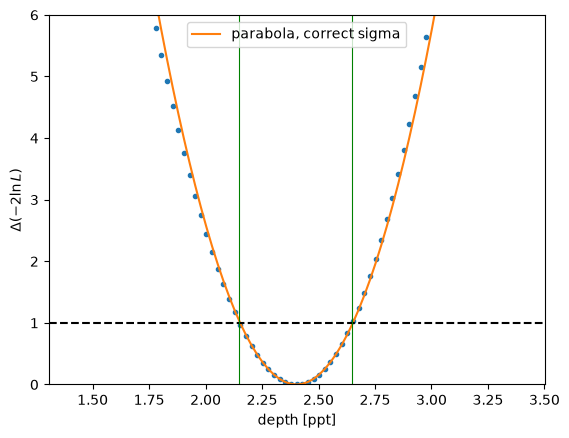

predicted coverage: 0.5204998778130465
simulated coverage: classmate 0.525, correct sigma 0.682


In [4]:
pr = load('p1c_profile')
dep = pr['depth_ppt'].to_numpy()
m2l = pr['minus2lnL'].to_numpy()
i = np.argmin(m2l)
h = dep[1] - dep[0]
curv = (m2l[i+1] - 2*m2l[i] + m2l[i-1])/h**2      # d^2(-2lnL)/d depth^2
# parabola through the points near the minimum for the best value
q = np.polyfit(dep[i-4:i+5], m2l[i-4:i+5], 2)
best = -q[1]/(2*q[0])
sig_classmate = 1/np.sqrt(curv)
sig_right = np.sqrt(2/curv)
print(f"best depth = {best:.3f} ppt, curvature = {curv:.2f} per ppt^2")
print(f"classmate sigma = {sig_classmate:.3f} ppt, correct sigma = {sig_right:.3f} ppt, ratio = {sig_right/sig_classmate:.3f}")

dm = m2l - m2l.min()
fine = np.linspace(dep[0], dep[-1], 20001)
inside = fine[np.interp(fine, dep, dm) <= 1]     # depths where -2lnL is within 1 of the min
lo, hi = inside[0], inside[-1]
print(f"Delta(-2lnL)=1 interval: {lo:.3f} to {hi:.3f} ppt -> -{best-lo:.3f} / +{hi-best:.3f}")

plt.plot(dep, dm, '.')
plt.plot(dep, (dep-best)**2/sig_right**2, label='parabola, correct sigma')
plt.axhline(1, ls='--', color='k')
plt.axvline(lo, color='g', lw=0.8)
plt.axvline(hi, color='g', lw=0.8)
plt.ylim(0, 6)
plt.xlabel('depth [ppt]')
plt.ylabel(r'$\Delta(-2\ln L)$')
plt.legend()
plt.show()

# coverage of +/- classmate sigma
print("predicted coverage:", 2*stats.norm.cdf(1/np.sqrt(2)) - 1)
rng = np.random.default_rng(11)
truth = 2.4
fake = rng.normal(truth, sig_right, 5000)
cover_cm = np.mean(np.abs(fake - truth) < sig_classmate)
cover_ok = np.mean(np.abs(fake - truth) < sig_right)
print(f"simulated coverage: classmate {cover_cm:.3f}, correct sigma {cover_ok:.3f}")

**ANSWER:**

1. Best depth $2.40 \pm 0.25$ ppt. The curvature of $-2\ln L$ is 32.1 ppt$^{-2}$, and since $-2\ln L = \chi^2$ we need $\sigma = \sqrt{2/32.1} = 0.25$ ppt. The classmate's $1/\sqrt{32.1} = 0.18$ ppt is too small by $\sqrt 2$, they treated the curvature of $-2\ln L$ like it was the curvature of $-\ln L$.

2. $\Delta(-2\ln L) = 1$ gives 2.150 to 2.649 ppt, i.e. -0.253/+0.246. Basically symmetric and the same as the curvature answer, so the profile is close to a parabola here.

3. Prediction: $\pm\sigma/\sqrt 2$ contains the truth when $|z| < 0.707$, which is 52%. Simulation with 5000 fake best fits around 2.4 ppt: 52.5% for the classmate and 68.2% with the correct sigma.

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

M2 = 10.32 -2.62 +3.50 Msun   (N = 8000)
classmate 1, variance: 10.6 Msun^2  (sd = 3.25 Msun)
classmate 2, 84th-16th: 6.12 Msun  vs one-sigma half width 3.06
classmate 3, sd/sqrt(8000): 0.036 Msun  (factor sqrt(N) = 89)
mean = 10.79, median = 10.32, skewness = 0.96


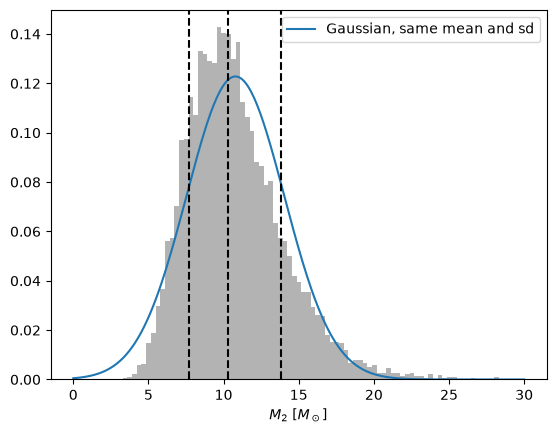

In [5]:
M2 = load('p1d_mass_samples')['M2_Msun'].to_numpy()
p16, p50, p84 = np.percentile(M2, [16, 50, 84])
print(f"M2 = {p50:.2f} -{p50-p16:.2f} +{p84-p50:.2f} Msun   (N = {len(M2)})")
sd = np.std(M2, ddof=1)
print(f"classmate 1, variance: {np.var(M2, ddof=1):.1f} Msun^2  (sd = {sd:.2f} Msun)")
print(f"classmate 2, 84th-16th: {p84-p16:.2f} Msun  vs one-sigma half width {(p84-p16)/2:.2f}")
print(f"classmate 3, sd/sqrt(8000): {sd/np.sqrt(len(M2)):.3f} Msun  (factor sqrt(N) = {np.sqrt(len(M2)):.0f})")
print(f"mean = {M2.mean():.2f}, median = {p50:.2f}, skewness = {stats.skew(M2):.2f}")

plt.hist(M2, 80, density=True, color='0.7')
xx = np.linspace(0, 30, 300)
plt.plot(xx, stats.norm.pdf(xx, M2.mean(), sd), label='Gaussian, same mean and sd')
for v in [p16, p50, p84]: plt.axvline(v, color='k', ls='--')
plt.xlabel(r'$M_2$ [$M_\odot$]')
plt.legend()
plt.show()

**ANSWER:**

1. $M_2 = 10.3^{+3.5}_{-2.6}\ M_\odot$.

2. (i) variance $= 10.6\ M_\odot^2$, that's $\sigma^2$ so the units are wrong, numerically ~3x the real $\sigma$. (ii) $p_{84} - p_{16} = 6.1\ M_\odot$ is the whole 68% width, about $2\sigma$, so 2x too big. (iii) ${\rm sd}/\sqrt{8000} = 0.036\ M_\odot$ is the Monte Carlo error on the posterior mean, not the uncertainty on the mass, too small by $\sqrt{8000} \approx 89$.

3. No. It has a tail to high mass (skewness 0.96, mean 10.8 vs median 10.3, upper error 3.5 vs lower 2.6). The Gaussian with the same mean and sd in the plot puts too much probability below ~6 and not enough in the tail.

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

rho = -0.851
marginal sigma_slope = 0.0490, fixed-intercept sigma_slope = 0.0257 (slice of 218 samples: 0.0246)
ratio = 0.525, sqrt(1-rho^2) = 0.525


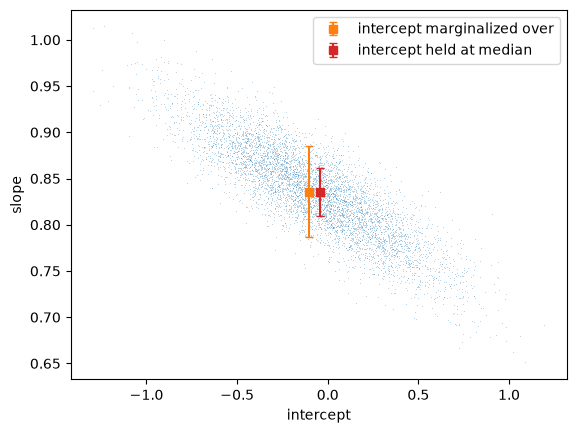

In [6]:
e = load('p1e_slope_intercept_samples')
slope = e['slope'].to_numpy()
icpt = e['intercept'].to_numpy()
Cs = np.cov(slope, icpt)
rho = Cs[0,1]/np.sqrt(Cs[0,0]*Cs[1,1])
s_marg = np.sqrt(Cs[0,0])
s_cond = np.sqrt(Cs[0,0] - Cs[0,1]**2/Cs[1,1])     # conditional sd of the slope
# sanity check: only keep samples whose intercept is very close to the median
b0 = np.median(icpt)
sl = np.abs(icpt - b0) < 0.05*np.std(icpt)
print(f"rho = {rho:.3f}")
print(f"marginal sigma_slope = {s_marg:.4f}, fixed-intercept sigma_slope = {s_cond:.4f} (slice of {sl.sum()} samples: {np.std(slope[sl]):.4f})")
print(f"ratio = {s_cond/s_marg:.3f}, sqrt(1-rho^2) = {np.sqrt(1-rho**2):.3f}")

a0 = np.median(slope)
plt.plot(icpt, slope, ',', alpha=0.3)
plt.errorbar(b0-0.03, a0, yerr=s_marg, fmt='s', color='C1', capsize=3, label='intercept marginalized over')
plt.errorbar(b0+0.03, a0, yerr=s_cond, fmt='s', color='C3', capsize=3, label='intercept held at median')
plt.xlabel('intercept')
plt.ylabel('slope')
plt.legend()
plt.show()

**ANSWER:**

1. Fixed intercept: 0.026 (conditional variance $C_{ss} - C_{sb}^2/C_{bb}$; the samples with intercept close to the median give 0.025). Marginal: 0.049.

2. Ratio 0.525, $\rho = -0.85$. For a 2-D Gaussian the conditional variance is $\sigma^2(1-\rho^2)$, so the ratio is $\sqrt{1-\rho^2} = 0.525$, and the more correlated they are the worse the classmate's number gets.

3. Only if the intercept is actually known from somewhere else, not from this same fit.

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

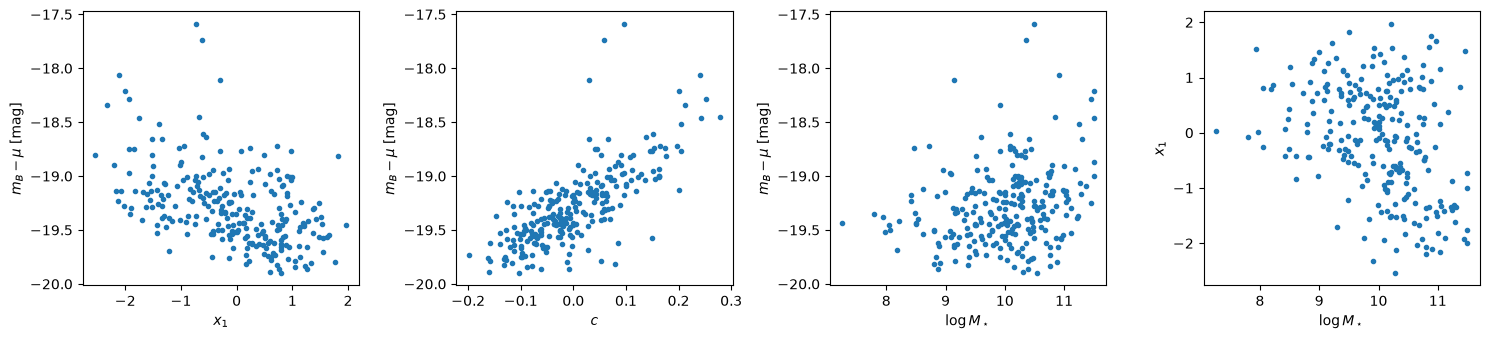

slope of hres vs x1: -0.174, vs c: 2.96
median hres: low mass -19.430, high mass -19.246
median x1: low mass 0.25, high mass -0.39
Pearson r(x1, logM) = -0.34
faintest residuals: [1.13 1.23 1.27 1.6  1.75]


In [7]:
from astropy.cosmology import FlatLambdaCDM
sn = load('p2_pantheon_sne')
z = sn['z'].to_numpy()
mB = sn['mB'].to_numpy()
x1 = sn['x1'].to_numpy()
col = sn['c'].to_numpy()
lmass = sn['host_logmass'].to_numpy()
mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
hres = mB - mu

fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
ax[0].plot(x1, hres, '.')
ax[0].set_xlabel('$x_1$')
ax[1].plot(col, hres, '.')
ax[1].set_xlabel('$c$')
ax[2].plot(lmass, hres, '.')
ax[2].set_xlabel(r'$\log M_\star$')
for a in ax[:3]: a.set_ylabel(r'$m_B - \mu$ [mag]')
ax[3].plot(lmass, x1, '.')
ax[3].set_xlabel(r'$\log M_\star$')
ax[3].set_ylabel('$x_1$')
plt.tight_layout()
plt.show()

print("slope of hres vs x1: %.3f, vs c: %.2f" % (np.polyfit(x1, hres, 1)[0], np.polyfit(col, hres, 1)[0]))
big = lmass > 10
print("median hres: low mass %.3f, high mass %.3f" % (np.median(hres[~big]), np.median(hres[big])))
print("median x1: low mass %.2f, high mass %.2f" % (np.median(x1[~big]), np.median(x1[big])))
print("Pearson r(x1, logM) = %.2f" % np.corrcoef(x1, lmass)[0,1])
print("faintest residuals:", np.round(np.sort(hres - np.median(hres))[-5:], 2))

**ANSWER:**

1. Plots above.

2. Residuals go down with $x_1$ (about $-0.17$ mag per unit $x_1$, broader = brighter) and up with $c$ (about $+3.0$ mag per unit $c$, redder = fainter). That's what Tripp expects with $\alpha, \beta > 0$.

3. Raw, the massive hosts actually look fainter (median -19.25 vs -19.43 mag), opposite to $\gamma<0$. That's because massive hosts have lower $x_1$ (last panel, median $-0.39$ vs $+0.25$), and low stretch SNe are fainter, so you need to fit $\alpha$ and $\gamma$ together.

4. Yes, three points sit ~1-1.5 mag above the rest, clearest in the $c$ plot.

5. $x_1$ and $c$ are dimensionless so $\alpha$, $\beta$ are in mag.

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

all 250: M, alpha, beta, gamma, sig_int = [-19.282   0.148   2.952  -0.027] 0.169
largest residuals [mag]: [('2003cq', np.float64(1.33)), ('2003kc', np.float64(1.3)), ('390259', np.float64(1.05)), ('PTSS-16efw', np.float64(0.39)), ('21062', np.float64(0.39))]
most negative: [-0.74 -0.63 -0.53]
removed: ['2003cq', '2003kc', '390259']  N left = 247
all 250: beta = 2.952 +/- 0.141, sig_int = 0.169 +/- 0.010 mag
cut: beta = 2.819 +/- 0.100, sig_int = 0.105 +/- 0.008 mag


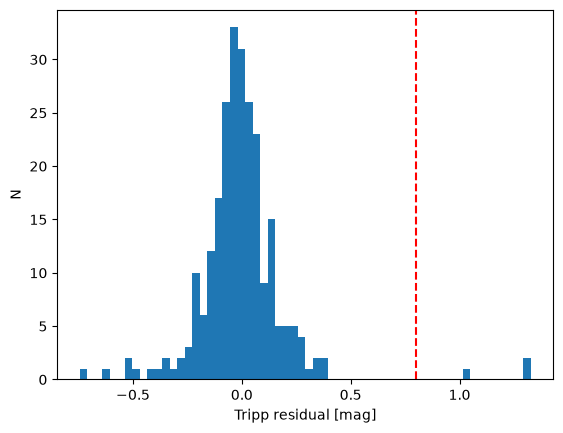

In [8]:
Ncov = np.zeros((len(sn), 3, 3))
Ncov[:,0,0] = sn['mB_err']**2
Ncov[:,1,1] = sn['x1_err']**2
Ncov[:,2,2] = sn['c_err']**2
Ncov[:,0,1] = Ncov[:,1,0] = sn['cov_mB_x1']
Ncov[:,0,2] = Ncov[:,2,0] = sn['cov_mB_c']
Ncov[:,1,2] = Ncov[:,2,1] = sn['cov_x1_c']
c_kms = 299792.458
sig_pec2 = ((5/np.log(10)) * (250/c_kms) / z)**2
massive = (lmass > 10).astype(float)

def neg2lnL(theta, mB, x1, col, good):
    M, alpha, beta, gamma, ln_s = theta
    # v^T C v written out term by term (see 2b)
    var = (Ncov[:,0,0] + alpha**2*Ncov[:,1,1] + beta**2*Ncov[:,2,2]
           + 2*alpha*Ncov[:,0,1] - 2*beta*Ncov[:,0,2] - 2*alpha*beta*Ncov[:,1,2])
    var = var + sig_pec2 + np.exp(2*ln_s)
    r = mB - mu - (M - alpha*x1 + beta*col + gamma*massive)
    terms = r**2/var + np.log(2*np.pi*var)
    return terms[good].sum()

def ln_prior(theta, gwidth=0.1):
    M, alpha, beta, gamma, ln_s = theta
    if not (-20 < M < -18.6 and -0.3 < alpha < 0.6 and 0 < beta < 5 and np.log(0.002) < ln_s < np.log(0.7)):
        return -np.inf
    return stats.norm.logpdf(gamma, 0, gwidth)

def ln_post(theta, good):
    lp = ln_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp - 0.5*neg2lnL(theta, mB, x1, col, good)

def num_hessian(f, p, h=1e-4):
    n = len(p)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            di = np.zeros(n)
            dj = np.zeros(n)
            di[i] = h
            dj[j] = h
            H[i,j] = (f(p+di+dj) - f(p+di-dj) - f(p-di+dj) + f(p-di-dj))/(4*h*h)
    return H

def nm(f, start):
    return minimize(f, start, method='Nelder-Mead', options={'maxiter': 40000, 'xatol': 1e-9, 'fatol': 1e-9})

# first pass with everything, to find the contaminants
allsn = np.ones(len(sn), bool)
r_all = nm(lambda t: neg2lnL(t, mB, x1, col, allsn), [-19.3, 0.15, 3.0, 0.0, np.log(0.1)])
M, alpha, beta, gamma, ln_s = r_all.x
res_all = hres - (M - alpha*x1 + beta*col + gamma*massive)
print("all 250: M, alpha, beta, gamma, sig_int =", np.round(r_all.x[:4], 3), round(np.exp(ln_s), 3))
order = np.argsort(res_all)[::-1]
print("largest residuals [mag]:", [(sn['name'][j], round(res_all[j], 2)) for j in order[:5]])
print("most negative:", np.round(np.sort(res_all)[:3], 2))
good = res_all < 0.8
print("removed:", list(sn['name'][~good]), " N left =", good.sum())

# what the 3 do to the fit: max likelihood with and without them, curvature errors
def ml_fit(sel, start):
    f = lambda t: neg2lnL(t, mB, x1, col, sel)
    r = nm(f, start)
    return r.x, np.sqrt(np.diag(2*np.linalg.inv(num_hessian(f, r.x))))
for lab, sel in [('all 250', allsn), ('cut', good)]:
    t, dt = ml_fit(sel, r_all.x)
    print(f"{lab}: beta = {t[2]:.3f} +/- {dt[2]:.3f}, sig_int = {np.exp(t[4]):.3f} +/- {np.exp(t[4])*dt[4]:.3f} mag")

plt.hist(res_all, 60)
plt.axvline(0.8, color='r', ls='--')
plt.xlabel('Tripp residual [mag]')
plt.ylabel('N')
plt.show()

**ANSWER:**

1. $\mathbf v^T C_i \mathbf v = \sigma_{m_B}^2 + \alpha^2\sigma_{x_1}^2 + \beta^2\sigma_c^2 + 2\alpha\,C_{m_B x_1} - 2\beta\,C_{m_B c} - 2\alpha\beta\,C_{x_1 c}$. The off-diagonal terms are there because $m_B$, $x_1$, $c$ come from one light curve fit so their errors are correlated, and the residual combines all three.

2. With $r_i = m_{B,i} - \mu(z_i) - M + \alpha x_{1,i} - \beta c_i - \gamma\Theta_i$:
$$-2\ln L = \sum_i \left[\frac{r_i^2}{\sigma_i^2} + \ln(2\pi\sigma_i^2)\right]$$
$\sigma_i^2$ depends on $\alpha, \beta, \sigma_{\rm int}$ so the log term stays, otherwise the fit could just inflate $\sigma_{\rm int}$.

3. Priors:
   - $M \sim U(-20, -18.6)$, wide around ~-19.3 for $H_0=70$
   - $\alpha \sim U(-0.3, 0.6)$, any sensible stretch coefficient (published ~0.15), sign not forced
   - $\beta \sim U(0, 5)$, redder has to be fainter, and 5 is well above the usual ~3
   - $\gamma \sim N(0, 0.1)$ mag, published steps are 0.05-0.1 mag and 2d needs a proper prior
   - $\ln\sigma_{\rm int} \sim U(\ln 0.002, \ln 0.7)$, flat in log since it's a scale and I don't know the order of magnitude

4. $\ln\sigma_{\rm int}$: stays positive, no preferred scale, and no wall at 0. The posterior ($\sigma_{\rm int}\approx 0.11$) is far from both edges anyway.

5. Removed. I fit all 250 by ML and looked at the residuals (histogram): 2003cq, 2003kc and 390259 are at +1.33, +1.30, +1.05 mag, the next biggest is +0.39 and the most negative -0.74. So I cut residual > 0.8 mag on the faint side only (they were made fainter), leaving 247. Cost is 3 SNe and a threshold I picked after looking, but nothing is between +0.39 and +1.05 so the exact value doesn't matter. Keeping them would push $\sigma_{\rm int}$ from $0.105 \pm 0.008$ to $0.169 \pm 0.010$ mag and $\beta$ from $2.82 \pm 0.10$ to $2.95 \pm 0.14$. The -0.74 one is bright so it's a real outlier, not planted.

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [9]:
import emcee, arviz as az, corner

r_map = nm(lambda t: -ln_post(t, good), r_all.x)
r_map = nm(lambda t: -ln_post(t, good), r_map.x)
theta_map = r_map.x
cov_map = np.linalg.inv(num_hessian(lambda t: -ln_post(t, good), theta_map))
err_map = np.sqrt(np.diag(cov_map))
labels = ['M', 'alpha', 'beta', 'gamma', 'ln_sig_int']
for nme, v, s in zip(labels, theta_map, err_map):
    print(f"MAP {nme} = {v:.4f} +/- {s:.4f}")

# four separate emcee runs, walkers scattered +/-4 curvature sigmas around the MAP
rng = np.random.default_rng(457)
nwalk, nstep, burn = 24, 6000, 1000
chains = []
for k in range(4):
    start = theta_map + 4*err_map*rng.uniform(-1, 1, (nwalk, 5))
    np.random.seed(100 + k)     # so the chains are reproducible
    sampler = emcee.EnsembleSampler(nwalk, 5, ln_post, args=(good,))
    sampler.run_mcmc(start, nstep, progress=False)
    print(f"chain {k}: acceptance {sampler.acceptance_fraction.mean():.2f}, tau =", np.round(sampler.get_autocorr_time(tol=0)))
    chains.append(sampler.get_chain(discard=burn))   # (step, walker, param)

post = {nme: np.array([ch[:, :, j].T.ravel() for ch in chains]) for j, nme in enumerate(labels)}
post['sig_int'] = np.exp(post['ln_sig_int'])
idata = az.from_dict({'posterior': post})
print(az.summary(idata)[['mean', 'sd', 'ess_bulk', 'ess_tail', 'r_hat']])

MAP M = -19.2938 +/- 0.0131
MAP alpha = 0.1436 +/- 0.0091
MAP beta = 2.8185 +/- 0.1001
MAP gamma = -0.0298 +/- 0.0179
MAP ln_sig_int = -2.2535 +/- 0.0783


chain 0: acceptance 0.55, tau = [54. 60. 59. 51. 56.]


chain 1: acceptance 0.55, tau = [53. 59. 52. 51. 55.]


chain 2: acceptance 0.55, tau = [58. 53. 66. 59. 59.]


chain 3: acceptance 0.55, tau = [58. 57. 58. 56. 52.]


                mean       sd ess_bulk ess_tail r_hat
M           -19.2938   0.0132     7703    16161  1.00
alpha         0.1436  0.00921     7723    15693  1.00
beta            2.82   0.1009     7429    15016  1.00
gamma        -0.0296   0.0181     7859    16001  1.00
ln_sig_int    -2.242   0.0792     7577    15283  1.00
sig_int       0.1066  0.00842     7577    15283  1.00


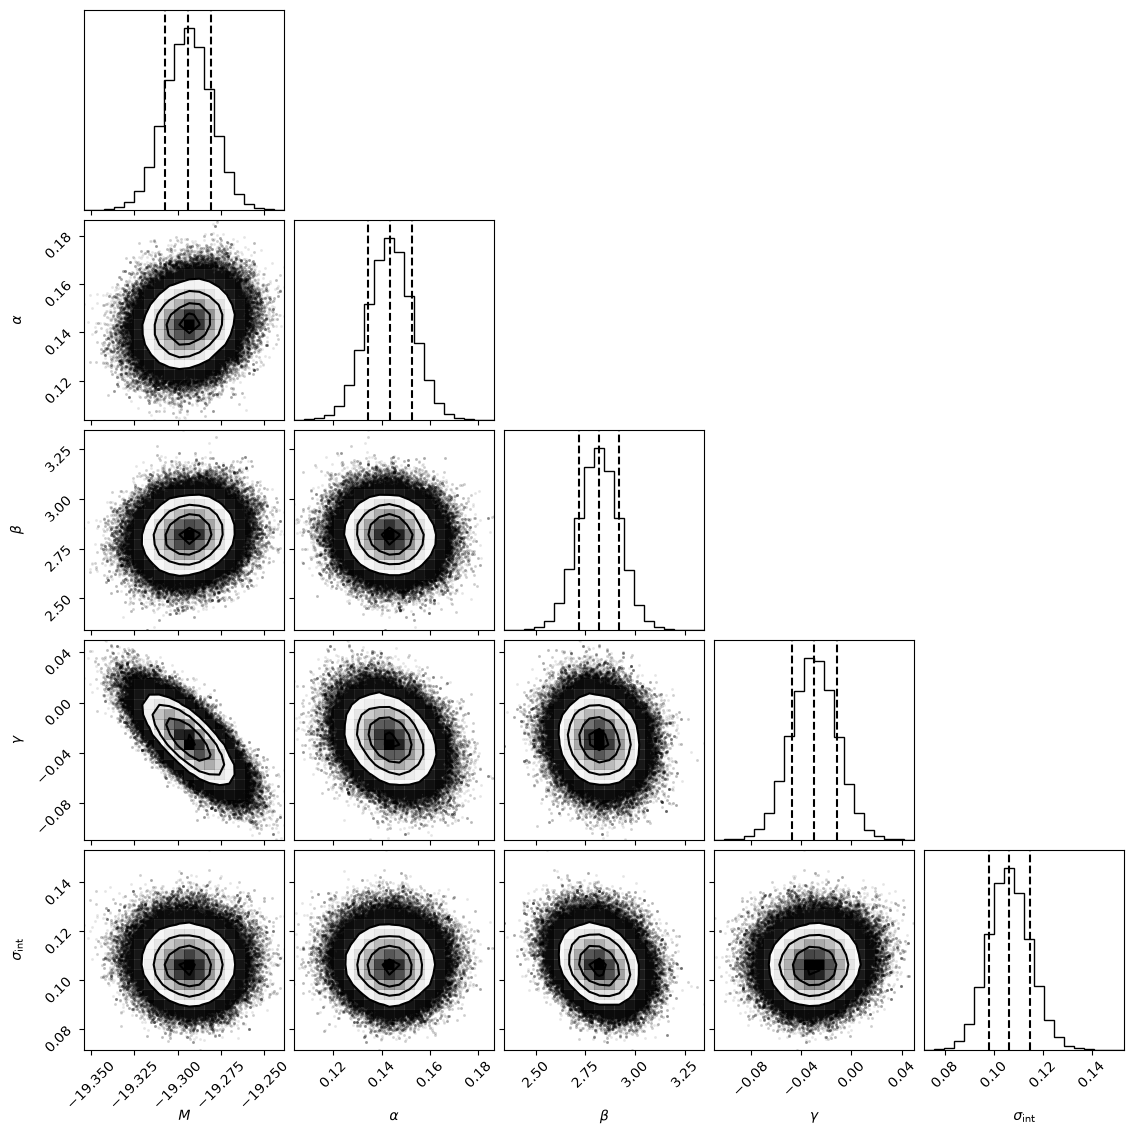

M = -19.2938 -0.0132 +0.0131
alpha = 0.1436 -0.0092 +0.0091
beta = 2.8198 -0.0996 +0.1006
gamma = -0.0297 -0.0180 +0.0180
sig_int = 0.1063 -0.0081 +0.0086
correlation matrix (M, alpha, beta, gamma, sig_int):
[[ 1.    0.16  0.12 -0.75 -0.05]
 [ 0.16  1.   -0.08 -0.29 -0.04]
 [ 0.12 -0.08  1.   -0.12 -0.24]
 [-0.75 -0.29 -0.12  1.    0.06]
 [-0.05 -0.04 -0.24  0.06  1.  ]]
gamma with M fixed: -0.0298 +/- 0.0118;  marginal sigma_gamma = 0.0181
ratio = 0.65, sqrt(1 - rho_Mg^2) = 0.66


In [10]:
flat = np.concatenate([ch.reshape(-1, 5) for ch in chains])
flat_plot = np.column_stack([flat[:, :4], np.exp(flat[:, 4])])
corner.corner(flat_plot, labels=[r'$M$', r'$\alpha$', r'$\beta$', r'$\gamma$', r'$\sigma_{\rm int}$'], quantiles=[0.16, 0.5, 0.84])
plt.show()
for j, nme in enumerate(['M', 'alpha', 'beta', 'gamma', 'sig_int']):
    q = np.percentile(flat_plot[:, j], [16, 50, 84])
    print(f"{nme} = {q[1]:.4f} -{q[1]-q[0]:.4f} +{q[2]-q[1]:.4f}")
print("correlation matrix (M, alpha, beta, gamma, sig_int):")
print(np.round(np.corrcoef(flat_plot.T), 2))

# fix M at the MAP and refit the rest
negpost_fixM = lambda t: -ln_post(np.concatenate([[theta_map[0]], t]), good)
r_fixM = nm(negpost_fixM, theta_map[1:])
sig_g_fixM = np.sqrt(np.linalg.inv(num_hessian(negpost_fixM, r_fixM.x))[2, 2])
sig_g_marg = np.std(flat[:, 3])
rho_Mg = np.corrcoef(flat[:, 0], flat[:, 3])[0, 1]
print(f"gamma with M fixed: {r_fixM.x[2]:.4f} +/- {sig_g_fixM:.4f};  marginal sigma_gamma = {sig_g_marg:.4f}")
print(f"ratio = {sig_g_fixM/sig_g_marg:.2f}, sqrt(1 - rho_Mg^2) = {np.sqrt(1-rho_Mg**2):.2f}")

**ANSWER:**

1. MAP: $M = -19.294 \pm 0.013$, $\alpha = 0.1436 \pm 0.0091$, $\beta = 2.82 \pm 0.10$, $\gamma = -0.030 \pm 0.018$, $\sigma_{\rm int} = 0.1050 \pm 0.0082$ (all mag, curvature errors). Then 4 separate emcee runs, 24 walkers each, walkers spread uniformly $\pm 4$ curvature sigmas around the MAP so they start wider than the posterior. 6000 steps, first 1000 dropped, $\tau \approx 51$-66 so ~100 $\tau$ per chain.

2. $\hat R = 1.00$ for all, ess_bulk 7400-7900, ess_tail 15000-16200. I'd have run longer for $\hat R > 1.01$, ESS under a few hundred, or chains shorter than 50 $\tau$.

3. $\alpha = 0.1436^{+0.0091}_{-0.0092}$ mag, $\beta = 2.82 \pm 0.10$ mag, $\gamma = -0.030 \pm 0.018$ mag, $\sigma_{\rm int} = 0.1063^{+0.0086}_{-0.0081}$ mag.

4. $M$ and $\gamma$ ($\rho = -0.75$): $M$ is set by the low mass hosts and $M+\gamma$ by the massive ones, so they trade off. Weaker: $\alpha$-$\gamma$ (-0.29) since $x_1$ depends on host mass, and $\beta$-$\sigma_{\rm int}$ (-0.24) since bigger $\beta$ puts more color error into $\sigma_i^2$. Fixing $M$ at the MAP gives $\sigma_\gamma = 0.012$ mag vs 0.018 marginal, ratio 0.65, $\approx\sqrt{1-0.75^2} = 0.66$ like in 1e. With $M$ fixed $\gamma$ would look like 2.5 sigma instead of 1.7.

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [11]:
def laplace_lnZ(gamma_free, gwidth):
    if gamma_free:
        f = lambda t: 0.5*neg2lnL(t, mB, x1, col, good) - ln_prior(t, gwidth)
        start = theta_map
    else:
        f = lambda t: 0.5*neg2lnL(np.concatenate([t[:3], [0], t[3:]]), mB, x1, col, good)
        start = np.delete(theta_map, 3)
    r = nm(f, start)
    r = nm(f, r.x)
    H = num_hessian(f, r.x)
    # -r.fun = ln L + ln prior(gamma) at the peak. The flat priors on M, alpha, beta, ln sig_int
    # are the same in both models, so their 1/volume factors cancel in the ratio and are left out.
    return -r.fun + 0.5*len(r.x)*np.log(2*np.pi) - 0.5*np.log(np.linalg.det(H)), r

lnZ0, r0 = laplace_lnZ(False, None)
for gw in [0.1, 0.2]:
    lnZ1, r1 = laplace_lnZ(True, gw)
    print(f"gamma prior N(0, {gw}): 2 ln B10 = {2*(lnZ1 - lnZ0):.2f}")

Nsn = good.sum()
lnL0 = -0.5*neg2lnL(np.concatenate([r0.x[:3], [0], r0.x[3:]]), mB, x1, col, good)
r1ml = nm(lambda t: neg2lnL(t, mB, x1, col, good), theta_map)
lnL1 = -0.5*r1ml.fun
BIC0 = -2*lnL0 + 4*np.log(Nsn)
BIC1 = -2*lnL1 + 5*np.log(Nsn)
print(f"lnL0 = {lnL0:.2f}, lnL1 = {lnL1:.2f}, 2 dlnL = {2*(lnL1-lnL0):.2f}")
print(f"BIC0 - BIC1 = {BIC0 - BIC1:.2f}")
print(f"gamma = {np.median(flat[:,3]):.3f} +/- {sig_g_marg:.3f};  -0.06 would be {0.06/sig_g_marg:.1f} sigma from zero")

gamma prior N(0, 0.1): 2 ln B10 = -0.71
gamma prior N(0, 0.2): 2 ln B10 = -2.00
lnL0 = 131.94, lnL1 = 133.36, 2 dlnL = 2.82
BIC0 - BIC1 = -2.69
gamma = -0.030 +/- 0.018;  -0.06 would be 3.3 sigma from zero


**ANSWER:**

1. Laplace with $\gamma \sim N(0, 0.1)$ mag in $M_1$ (0.1 is about the biggest step anyone has claimed). The other priors are the same in both models and cancel. $2\ln B_{1,0} = -0.7$. With $N(0, 0.2)$ it's $-2.0$, a drop of 1.3, close to $2\ln 2$ since the posterior is much narrower than the prior so doubling the prior halves the Occam factor.

2. ${\rm BIC}_0 - {\rm BIC}_1 = -2.7$ ($2\Delta\ln L = 2.8$, penalty $\ln 247 = 5.5$).

3. All weakly favor no step: -0.7 is weak, -2.0 and -2.7 are right at the edge of positive for $M_0$, and it depends on the prior width so I wouldn't claim there's no step. $\gamma = -0.030 \pm 0.018$ mag is 1.7 sigma from both 0 and -0.06. A -0.06 step would be 3.3 sigma here, so 250 SNe probably would of seen one that big, but not one half that size.

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

**Plan (before running):** 50 fake datasets on my 247 supernovae (their z, host mass, and observed $x_1$, $c$ used as the true values) with $M=-19.35$, $\alpha=0.13$, $\beta=3.2$, $\gamma=-0.06$, $\sigma_{\rm int}=0.10$. Each SN gets noise in $m_B$, $x_1$, $c$ from its own $C_i$, plus pec. velocity and $\sigma_{\rm int}$ in $m_B$. Fit each one by ML with curvature errors. I'll call it a failure if the fraction of $\pm1\sigma$ intervals containing the truth for $\alpha$, $\beta$ or $\gamma$ is outside 55-81% (2 binomial sigmas around 68% for 50 sets).

fraction of 68% intervals containing the truth (M, alpha, beta, gamma, ln sig_int): [0.76 0.66 0.04 0.64 0.78]
average (fit - truth)/error: [-0.39 -0.57 -2.91  0.46 -0.01]


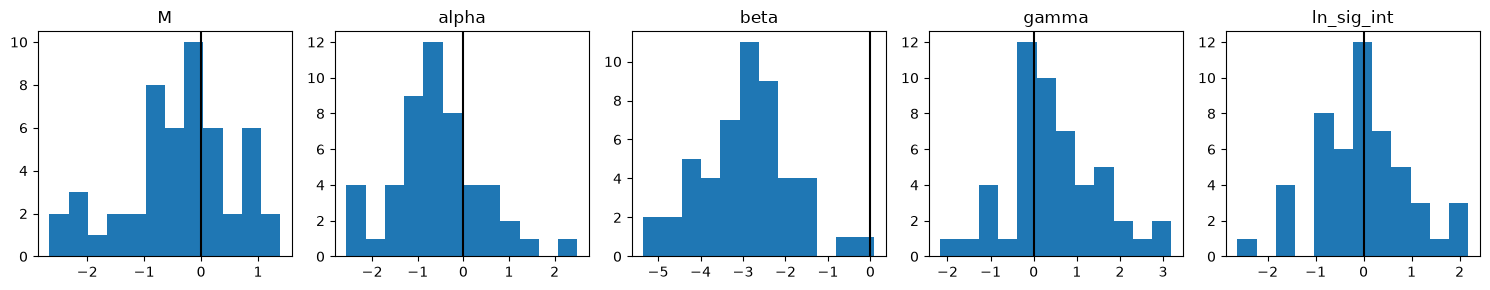

In [12]:
# fake supernovae: true x1, c = the observed ones, noise drawn from each SN's own 3x3 covariance
truth = np.array([-19.35, 0.13, 3.2, -0.06, np.log(0.10)])
rng = np.random.default_rng(2)
idx = np.where(good)[0]

def fake_set(noisy_x1c=True):
    M, alpha, beta, gamma, ln_s = truth
    fmB, fx1, fc = mB.copy(), x1.copy(), col.copy()
    for j in idx:
        dm, dx, dc = rng.multivariate_normal(np.zeros(3), Ncov[j])
        if not noisy_x1c:
            dx = dc = 0
        fmB[j] = mu[j] + M - alpha*x1[j] + beta*col[j] + gamma*massive[j] + dm + rng.normal(0, np.sqrt(sig_pec2[j] + np.exp(2*ln_s)))
        fx1[j] = x1[j] + dx
        fc[j] = col[j] + dc
    return fmB, fx1, fc

def zscores(nsets, noisy_x1c=True):
    out = []
    for it in range(nsets):
        fmB, fx1, fc = fake_set(noisy_x1c)
        f = lambda t: neg2lnL(t, fmB, fx1, fc, good)
        r = nm(f, truth + [0.02, 0.01, 0.1, 0.02, 0.1])
        r = nm(f, r.x)
        err = np.sqrt(np.diag(2*np.linalg.inv(num_hessian(f, r.x))))
        out.append((r.x - truth)/err)
    return np.array(out)

zz = zscores(50)
print("fraction of 68% intervals containing the truth (M, alpha, beta, gamma, ln sig_int):", np.round(np.mean(np.abs(zz) < 1, axis=0), 2))
print("average (fit - truth)/error:", np.round(zz.mean(axis=0), 2))

fig, ax = plt.subplots(1, 5, figsize=(15, 3))
for j in range(5):
    ax[j].hist(zz[:, j], 12)
    ax[j].set_title(labels[j])
    ax[j].axvline(0, color='k')
plt.tight_layout()
plt.show()

In [13]:
# same thing but with no noise added to x1 and c (only to mB)
zz_ctrl = zscores(50, noisy_x1c=False)
print("no x1/c noise - coverage:", np.round(np.mean(np.abs(zz_ctrl) < 1, axis=0), 2))
print("average (fit - truth)/error:", np.round(zz_ctrl.mean(axis=0), 2))

no x1/c noise - coverage: [0.58 0.64 0.6  0.74 0.14]
average (fit - truth)/error: [-0.36 -0.12 -0.11  0.34 -1.87]


**ANSWER:**

It failed for $\beta$: only 4% of the intervals contain $\beta = 3.2$ and the average $(\hat\beta - \beta)/\sigma$ is -2.9, so $\beta$ comes out ~0.3 lower then the truth. $\alpha$ (66%) and $\gamma$ (64%) pass.

I think this is the errors-in-$x$ attenuation from Day 10, the colors have errors (~0.03) that aren't small compared to their spread (~0.09), and adding $\beta^2\sigma_c^2$ to the variance makes the error bar bigger but doesn't remove the bias. To check it's not a bug I reran with noise only in $m_B$: then $\beta$ coverage is 60% and the average is -0.11, so the bias goes away. ($\sigma_{\rm int}$ comes out low in that run, expected since the model still adds color/stretch error that isn't in the fake data. $\gamma$ is shifted a bit toward 0 in both runs, +0.3 to +0.5, which I didnt chase down.)

So my real $\beta = 2.82 \pm 0.10$ is probably biased low by a few sigma. Fixing it would mean modelling the true colors as latent variables (like the Lab 04 generative fit) or correcting with simulations like this. $\gamma$ passed so 2d shouldn't change.

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

600 WDs, mass errors: median 0.012, max 0.069 Msun
clip range 0.08 to 1.14 Msun; removed 14 stars, masses: [1.144 1.145 1.147 1.151 1.156 1.161 1.166 1.213 1.257 1.263 1.278 1.279
 1.282 1.298]
stars below 0.45 Msun: 38  above 1.0 Msun: 26


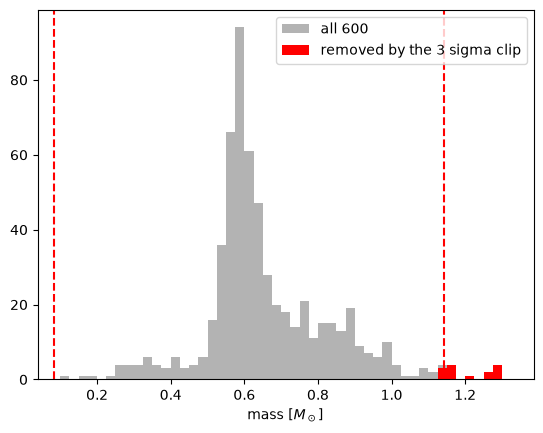

In [14]:
wd = load('p3_wd_masses')
mass = wd['mass_Msun'].to_numpy()
merr = wd['mass_err_Msun'].to_numpy()
print(f"{len(mass)} WDs, mass errors: median {np.median(merr):.3f}, max {merr.max():.3f} Msun")

# (1) the 3 sigma clip, exactly as in ai_solution
med, sd = np.median(mass), np.std(mass)
clip = np.abs(mass - med) < 3*sd
print(f"clip range {med-3*sd:.2f} to {med+3*sd:.2f} Msun; removed {np.sum(~clip)} stars, masses:", np.sort(mass[~clip]))
print("stars below 0.45 Msun:", np.sum(mass < 0.45), " above 1.0 Msun:", np.sum(mass > 1.0))
plt.hist(mass, np.arange(0.1, 1.35, 0.025), color='0.7', label='all 600')
plt.hist(mass[~clip], np.arange(0.1, 1.35, 0.025), color='r', label='removed by the 3 sigma clip')
plt.axvline(med+3*sd, color='r', ls='--')
plt.axvline(med-3*sd, color='r', ls='--')
plt.xlabel(r'mass [$M_\odot$]')
plt.legend()
plt.show()

       ess_bulk r_hat
mu1        1353  1.00
sigma1     1176  1.00
mu2        1223  1.00
sigma2     1202  1.00
f          1182  1.00
corrected fit, all 600 (median -16 +84):
mu1     = 0.5900 -0.0030 +0.0032
sigma1  = 0.0332 -0.0029 +0.0030
mu2     = 0.7194 -0.0134 +0.0132
sigma2  = 0.2191 -0.0090 +0.0095
f       = 0.4445 -0.0321 +0.0311


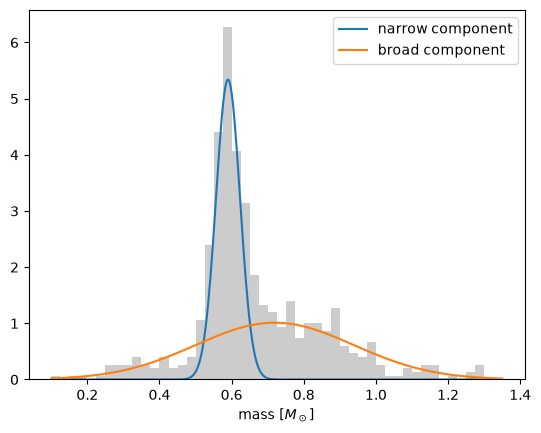

In [15]:
# the AI model, with each star's own error added in quadrature (err = 0 gives back the AI version)
def wd_lnprob(p, m, err):
    mu1, s1, mu2, s2, f = p
    if not (0.3 < mu1 < 1.3 and 0.3 < mu2 < 1.3 and 0.005 < s1 < 0.5 and 0.005 < s2 < 0.5 and 0 < f < 1):
        return -np.inf
    return np.sum(np.log(f*stats.norm.pdf(m, mu1, np.sqrt(s1**2 + err**2)) + (1-f)*stats.norm.pdf(m, mu2, np.sqrt(s2**2 + err**2))))

wd_names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']

# corrected run: all 600 stars, errors included, four separate ensembles from spread starts
def run_wd(m, err, nstep=6000, seed=5):
    g = np.random.default_rng(seed)
    pstart = nm(lambda p: -wd_lnprob(p, m, err), [0.59, 0.035, 0.72, 0.2, 0.45]).x
    out = []
    for k in range(4):
        st = pstart*(1 + g.uniform(-0.3, 0.3, (32, 5)))
        np.random.seed(seed + k)
        s = emcee.EnsembleSampler(32, 5, wd_lnprob, args=(m, err))
        s.run_mcmc(st, nstep, progress=False)
        out.append(s.get_chain(discard=1000))
    return out

wd_ch = run_wd(mass, merr)
wd_post = {nme: np.array([ch[:, :, j].T.ravel() for ch in wd_ch]) for j, nme in enumerate(wd_names)}
print(az.summary(az.from_dict({'posterior': wd_post}))[['ess_bulk', 'r_hat']])
wd_flat = np.concatenate([ch.reshape(-1, 5) for ch in wd_ch])
print("corrected fit, all 600 (median -16 +84):")
for j, nme in enumerate(wd_names):
    q = np.percentile(wd_flat[:, j], [16, 50, 84])
    print(f"{nme:7s} = {q[1]:.4f} -{q[1]-q[0]:.4f} +{q[2]-q[1]:.4f}")

xx = np.linspace(0.1, 1.35, 400)
mu1, s1, mu2, s2, f = np.median(wd_flat, axis=0)
plt.hist(mass, np.arange(0.1, 1.35, 0.025), density=True, color='0.8')
plt.plot(xx, f*stats.norm.pdf(xx, mu1, s1), label='narrow component')
plt.plot(xx, (1-f)*stats.norm.pdf(xx, mu2, s2), label='broad component')
plt.xlabel(r'mass [$M_\odot$]')
plt.legend()
plt.show()

In [16]:
# (1) what the clip alone does: same corrected likelihood, clipped sample
wd_ch_clip = run_wd(mass[clip], merr[clip])
clip_flat = np.concatenate([ch.reshape(-1, 5) for ch in wd_ch_clip])
for j, nme in enumerate(wd_names):
    q = np.percentile(clip_flat[:, j], [16, 50, 84])
    print(f"clipped {nme:7s} = {q[1]:.4f} -{q[1]-q[0]:.4f} +{q[2]-q[1]:.4f}")

# (3) same 600 stars, but ignoring the mass errors like the AI notebook does
wd_ch_noerr = run_wd(mass, 0*merr)
noerr_flat = np.concatenate([ch.reshape(-1, 5) for ch in wd_ch_noerr])
for j, nme in enumerate(wd_names):
    q = np.percentile(noerr_flat[:, j], [16, 50, 84])
    print(f"no errors {nme:7s} = {q[1]:.4f} -{q[1]-q[0]:.4f} +{q[2]-q[1]:.4f}")
print("stars with mass error > 0.033 Msun (about sigma1):", np.sum(merr > 0.033))

clipped mu1     = 0.5891 -0.0032 +0.0033
clipped sigma1  = 0.0312 -0.0031 +0.0031
clipped mu2     = 0.6925 -0.0123 +0.0119
clipped sigma2  = 0.1933 -0.0084 +0.0087
clipped f       = 0.4250 -0.0356 +0.0332


no errors mu1     = 0.5898 -0.0031 +0.0033
no errors sigma1  = 0.0361 -0.0029 +0.0030
no errors mu2     = 0.7179 -0.0135 +0.0131
no errors sigma2  = 0.2177 -0.0091 +0.0094
no errors f       = 0.4343 -0.0324 +0.0315
stars with mass error > 0.033 Msun (about sigma1): 29


In [17]:
# (2) the AI validation: can it fail?
# make fake samples from the corrected fit (with real-looking mass errors), run the AI pipeline on them
# (3 sigma clip, no errors), and also run the AI-style check (simulate from its own fit, refit)
true_wd = np.median(wd_flat, axis=0)
g = np.random.default_rng(8)
pipeline = []
selfcheck = []
for it in range(20):
    n2 = g.binomial(600, 1 - true_wd[4])
    err = merr[g.integers(0, 600, 600)]
    fake = np.concatenate([g.normal(true_wd[0], true_wd[1], 600 - n2), g.normal(true_wd[2], true_wd[3], n2)])
    fake = fake + g.normal(0, err)
    keep = np.abs(fake - np.median(fake)) < 3*np.std(fake)
    p_ai = nm(lambda p: -wd_lnprob(p, fake[keep], 0), true_wd).x
    pipeline.append(p_ai)
    # the AI notebook's check: simulate from its own answer, no clip, no errors
    n2b = g.binomial(keep.sum(), 1 - p_ai[4])
    sim = np.concatenate([g.normal(p_ai[0], p_ai[1], keep.sum() - n2b), g.normal(p_ai[2], p_ai[3], n2b)])
    p_sim = nm(lambda p: -wd_lnprob(p, sim, 0), p_ai).x
    selfcheck.append(100*(p_sim - p_ai)/p_ai)
pipeline = np.array(pipeline)
selfcheck = np.array(selfcheck)
print("truth:              ", np.round(true_wd, 4))
print("AI pipeline, mean:  ", np.round(pipeline.mean(axis=0), 4))
print("bias / scatter:     ", np.round((pipeline.mean(axis=0) - true_wd)/pipeline.std(axis=0), 1))
print("AI self-check, mean % difference:", np.round(selfcheck.mean(axis=0), 1))

truth:               [0.59   0.0332 0.7194 0.2191 0.4445]
AI pipeline, mean:   [0.5894 0.0354 0.7026 0.1971 0.4148]
bias / scatter:      [-0.2  0.9 -1.2 -1.8 -0.9]
AI self-check, mean % difference: [-0.1  3.1  0.4 -1.9  2.4]


**REFEREE REPORT:**

I ran `ai_solution.ipynb` on my file (600 WDs) and it runs fine, but there are three real problems. To show them I used its code above with my path.

**1. The 3 sigma clip throws away the thing we're studying.** It uses `np.std` of everything (0.18 $M_\odot$), which is inflated by the the tails. Around the median (0.61) the low edge is 0.08 $M_\odot$ and removes nothing, and the high edge is 1.14 $M_\odot$ and removes 14 stars, all massive WDs at 1.14-1.30 $M_\odot$ with normal mass errors (~0.01). That's the massive tail Kilic et al. talk about. Fitting the clipped sample instead of all 600 (same corrected likelihood as below) moves $\mu_2$ from $0.719 \pm 0.013$ to $0.692 \pm 0.012\ M_\odot$ and $\sigma_2$ from $0.2191^{+0.0095}_{-0.0090}$ to $0.1933^{+0.0087}_{-0.0084}\ M_\odot$, so the second population looks lighter and narrower by 2-3 sigma. Instead: don't clip on the variable you're modelling, add an outlier component if needed. I keep all 600.

**2. The validation can't fail.** It simulates from its own best fit, with no clip and no mass errors, and refits starting at the truth, so the only thing it checks is that the sampler gives back what it was given. To show it misses real problems I made 20 fake samples from the corrected fit below (with mass errors drawn from my file) and ran the AI pipeline on them (clip + no errors). On average it gets $\mu_2$ = 0.703 instead of 0.719 and $\sigma_2$ = 0.197 instead of 0.219 $M_\odot$ (-1.2 and -1.8 times the scatter between fakes), and $\sigma_1$ too wide (0.0354 vs 0.0332) because the errors are ignored. The AI style check on the same fakes still gives back its own input to within 3% on average, so it would have said "validated" every time. Instead: simulate from something realistic (errors included, clip included if you clip), many times, and compare with the truth you put in.

**3. The mass errors are ignored.** The notebook says they're "far smaller than the population widths" so it drops them. That's fine for the broad component ($\sigma_2 \approx 0.22$) but not obviously for the narrow one ($\sigma_1 \approx 0.03$), and 29 of my stars have errors bigger than 0.033 $M_\odot$. Fitting all 600 with and without the errors: $\sigma_1 = 0.0361 \pm 0.0030$ without vs $0.0332^{+0.0030}_{-0.0029}\ M_\odot$ with, so ignoring them makes the narrow peak ~9% too wide (about 1 sigma). The other parameters move by much less than their errors. So on my file it's a small effect, it would matter more for a sample with bigger errors (fainter or cooler WDs) or a narrower peak. Instead: use $\sigma_k^2 + e_i^2$ for each star in each component. With that (and no clip) I get $\mu_1 = 0.5900^{+0.0032}_{-0.0030}$, $\sigma_1 = 0.0332^{+0.0030}_{-0.0029}$, $\mu_2 = 0.719 \pm 0.013$, $\sigma_2 = 0.2191^{+0.0095}_{-0.0090}$ (all $M_\odot$), $f = 0.444^{+0.031}_{-0.032}$.

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

1. I used Claude Code. I made sure I understood the problem first, then prompted it to get the code I needed and help with the write-up, and checked whether the results were right. It got a few things wrong. It expected the 2e test to pass, and when it didn't, the control run with no noise in $x_1$ and $c$ was what showed it was attenuation and not a bug. Its first corrected WD run had stuck walkers, which showed up as the mean and median of $\sigma_1$ disagreeing in `az.summary` ($\hat R$ 1.02), so I restarted closer to the optimum. And it didn't seed emcee, so the MCMC numbers changed every time I did Restart & Run All and stopped matching the text, which I fixed with `np.random.seed`.

2. Without checking, 2e would say the pipeline passes and I'd report $\beta$ as unbiased when it's a few sigma low. The corrected WD numbers in Part 3 would also have come from a run with stuck walkers.

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.